<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/Tugas2_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Instalasi Library


In [ ]:
!pip install -q annoy faiss-cpu hnswlib scikit-learn pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Import Library dan Konfigurasi
Konfigurasi `N_QUERIES` dapat disesuaikan. Untuk dataset sangat besar, mulai dari 100 query agar waktu eksperimen tetap terkendali.

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import faiss
import hnswlib

FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]
K = 10
N_QUERIES = 100
RANDOM_STATE = 42
print('Konfigurasi siap.')

Konfigurasi siap.


## 3. Memuat Dataset Micro Spotify
Unduh dataset pertama dari Kaggle sesuai instruksi modul. Jika memakai Google Colab, unggah file CSV melalui panel Files atau gunakan `files.upload()`. Pastikan file yang dipilih adalah dataset pertama, bukan dataset kedua.

In [ ]:
import os
import glob
import kagglehub

# Download dataset dari Kaggle menggunakan KaggleHub
dataset_path = kagglehub.dataset_download(
    'bwandowando/spotify-songs-with-attributes-and-lyrics'
)
print('Folder dataset:', dataset_path)

# Cari seluruh file CSV di dalam folder dataset
csv_files = glob.glob(os.path.join(dataset_path, '**', '*.csv'), recursive=True)
print('\nDaftar file CSV yang ditemukan:')
for i, file in enumerate(csv_files):
    print(f'{i}: {file}')

if not csv_files:
    raise FileNotFoundError(
        'Tidak ditemukan file CSV pada dataset. Periksa kembali hasil download Kaggle.'
    )

# Pilih CSV yang memiliki semua fitur numerik yang diperlukan oleh praktikum
required_features = set(FEATURES)
matching_csv = []
for file in csv_files:
    try:
        preview = pd.read_csv(file, nrows=5)
        preview.columns = preview.columns.astype(str).str.strip()
        available_columns = set(preview.columns)
        if required_features.issubset(available_columns):
            matching_csv.append(file)
    except Exception as e:
        print(f'Melewati file {file}: {e}')

if not matching_csv:
    raise ValueError(
        'Tidak ada CSV yang memiliki seluruh kolom fitur yang dibutuhkan: '
        + ', '.join(FEATURES)
        + '. Periksa daftar CSV di atas dan pastikan dataset Kaggle yang digunakan benar.'
    )

# Jika ada beberapa kandidat, prioritaskan nama spotify_songs.csv bila tersedia
matching_csv = sorted(
    matching_csv,
    key=lambda f: (0 if os.path.basename(f).lower() == 'spotify_songs.csv' else 1, f.lower())
)
CSV_PATH = matching_csv[0]
print('\nFile CSV yang dipilih:', CSV_PATH)

# Muat dataset lengkap
df = pd.read_csv(CSV_PATH)
df.columns = df.columns.astype(str).str.strip()
print('Ukuran dataset:', df.shape)
display(df.head())

100%|██████████| 894M/894M [00:13<00:00, 70.3MB/s]

Extracting files...


Folder dataset: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20

Daftar file CSV yang ditemukan:
0: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv
1: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_lyrics_and_timestamps.csv

File CSV yang dipilih: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv
Ukuran dataset: (955320, 17)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


## 4. Memilih Fitur Numerik dan Membersihkan Data
Gunakan sembilan fitur numerik yang disebutkan dalam boilerplate modul. Baris dengan nilai kosong atau nilai non-finite pada fitur tersebut dihapus agar StandardScaler dan indeks nearest neighbor dapat memproses data dengan benar.

In [ ]:
missing_columns = [col for col in FEATURES if col not in df.columns]
if missing_columns:
    raise ValueError(f'Kolom fitur tidak ditemukan: {missing_columns}. '
                     'Periksa apakah file yang dipilih adalah dataset pertama Micro Spotify.')

X_df = df[FEATURES].apply(pd.to_numeric, errors='coerce')
valid_mask = np.isfinite(X_df.to_numpy()).all(axis=1)
X_df = X_df.loc[valid_mask].copy()
df_clean = df.loc[valid_mask].copy()
X = X_df.to_numpy(dtype=np.float32)

print('Jumlah baris setelah pembersihan:', len(X))
print('Jumlah fitur:', X.shape[1])
print('Fitur:', FEATURES)

Jumlah baris setelah pembersihan: 955320
Jumlah fitur: 9
Fitur: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


## 5. Membagi Database dan Query serta Standardisasi
Pisahkan sebagian track sebagai query dan sisanya sebagai database indeks. StandardScaler di-fit pada database, kemudian transformasi yang sama diterapkan pada query. Dengan cara ini pencarian tidak mengembalikan track yang sama sebagai tetangga dirinya sendiri.

In [ ]:
if len(X) <= K + 1:
    raise ValueError('Jumlah baris valid terlalu sedikit untuk eksperimen.')

rng = np.random.default_rng(RANDOM_STATE)
all_indices = rng.permutation(len(X))
n_queries = min(N_QUERIES, max(1, len(X) // 10))
query_rows = all_indices[:n_queries]
db_rows = all_indices[n_queries:]

X_db_raw = X[db_rows]
X_query_raw = X[query_rows]

scaler = StandardScaler()
X_db = scaler.fit_transform(X_db_raw).astype(np.float32)
X_query = scaler.transform(X_query_raw).astype(np.float32)

print('Database vectors:', X_db.shape)
print('Query vectors:', X_query.shape)
print('Rata-rata fitur database setelah scaling (mendekati 0):', np.round(X_db.mean(axis=0), 3))

Database vectors: (955220, 9)
Query vectors: (100, 9)
Rata-rata fitur database setelah scaling (mendekati 0): [-0.  0.  0. -0. -0.  0. -0.  0.  0.]


## 6. Exact Nearest Neighbor sebagai Ground Truth
Scikit-learn `NearestNeighbors` dengan `algorithm='brute'` digunakan untuk menghitung 10 tetangga terdekat secara exact. Indeks hasilnya menjadi acuan untuk mengevaluasi hasil ANNOY, FAISS IVF, dan HNSW. Waktu fitting dan waktu query dicatat terpisah.

In [ ]:
exact_nn = NearestNeighbors(n_neighbors=K, algorithm='brute', metric='euclidean')
t0 = time.perf_counter()
exact_nn.fit(X_db)
exact_build_time = time.perf_counter() - t0

t0 = time.perf_counter()
exact_distances, exact_indices = exact_nn.kneighbors(X_query)
exact_query_seconds = time.perf_counter() - t0
exact_query_ms = exact_query_seconds * 1000 / len(X_query)

print('Exact NN build/fit time:', round(exact_build_time, 4), 's')
print('Exact NN query time:', round(exact_query_ms, 4), 'ms/query')
print('Contoh indeks tetangga query pertama:', exact_indices[0])
print('Contoh jarak query pertama:', np.round(exact_distances[0], 4))

Exact NN build/fit time: 0.0116 s
Exact NN query time: 6.0218 ms/query
Contoh indeks tetangga query pertama: [202295 243529 396996 105147 418866 235424 353716  26354  91293 609722]
Contoh jarak query pertama: [0.2921 0.3196 0.3278 0.3301 0.3321 0.3378 0.3395 0.3448 0.3588 0.3659]


## 7. Fungsi Evaluasi Recall@K
Recall@10 menghitung proporsi tetangga dari hasil metode yang juga terdapat pada hasil Exact NN. Nilai 1.0 berarti seluruh tetangga pada top-10 cocok dengan ground truth.

In [ ]:
def recall_at_k(predicted, ground_truth, k=K):
    total_matches = 0
    for pred, truth in zip(predicted, ground_truth):
        total_matches += len(set(np.asarray(pred[:k]).tolist()) &
                               set(np.asarray(truth[:k]).tolist()))
    return total_matches / (len(ground_truth) * k)

print('Recall Exact NN terhadap dirinya sendiri:',
      recall_at_k(exact_indices, exact_indices))

Recall Exact NN terhadap dirinya sendiri: 1.0


## 8. ANNOY
Bangun indeks ANNOY menggunakan metrik Euclidean. Build time mencakup penambahan item dan pembangunan tree. Query time merupakan waktu rata-rata pencarian per query.

In [ ]:
annoy_index = AnnoyIndex(X_db.shape[1], 'euclidean')
t0 = time.perf_counter()
for i, vector in enumerate(X_db):
    annoy_index.add_item(i, vector.tolist())
annoy_index.build(10)
annoy_build_time = time.perf_counter() - t0

t0 = time.perf_counter()
annoy_indices = [annoy_index.get_nns_by_vector(q.tolist(), K)
                 for q in X_query]
annoy_query_seconds = time.perf_counter() - t0
annoy_indices = np.asarray(annoy_indices, dtype=np.int64)
annoy_query_ms = annoy_query_seconds * 1000 / len(X_query)
annoy_recall = recall_at_k(annoy_indices, exact_indices)

print('ANNOY build time:', round(annoy_build_time, 4), 's')
print('ANNOY query time:', round(annoy_query_ms, 4), 'ms/query')
print('ANNOY Recall@10:', round(annoy_recall, 4))

ANNOY build time: 31.8025 s
ANNOY query time: 0.0637 ms/query
ANNOY Recall@10: 0.828


## 9. FAISS IVF
Gunakan FAISS `IndexIVFFlat` agar FAISS berperan sebagai indeks approximate. `nlist` menentukan jumlah inverted lists dan `nprobe` menentukan jumlah list yang diperiksa saat pencarian. Build time mencakup training dan penambahan vektor.

In [ ]:
dimension = X_db.shape[1]
nlist = min(100, max(1, len(X_db) // 40))
quantizer = faiss.IndexFlatL2(dimension)
faiss_index = faiss.IndexIVFFlat(quantizer, dimension, nlist, faiss.METRIC_L2)

t0 = time.perf_counter()
faiss_index.train(X_db)
faiss_index.add(X_db)
faiss_build_time = time.perf_counter() - t0
faiss_index.nprobe = min(10, nlist)

t0 = time.perf_counter()
faiss_distances, faiss_indices = faiss_index.search(X_query, K)
faiss_query_seconds = time.perf_counter() - t0
faiss_query_ms = faiss_query_seconds * 1000 / len(X_query)
faiss_recall = recall_at_k(faiss_indices, exact_indices)

print('FAISS IVF build time:', round(faiss_build_time, 4), 's')
print('FAISS IVF query time:', round(faiss_query_ms, 4), 'ms/query')
print('FAISS IVF Recall@10:', round(faiss_recall, 4))

FAISS IVF build time: 0.3034 s
FAISS IVF query time: 0.9909 ms/query
FAISS IVF Recall@10: 0.996


## 10. HNSW
Bangun indeks HNSW menggunakan metrik L2. Parameter `M=16` dan `ef_construction=200` digunakan pada proses pembangunan, sedangkan `ef=100` digunakan saat pencarian. Waktu pembangunan dan pencarian dicatat terpisah.

In [12]:
hnsw_index = hnswlib.Index(space='l2', dim=dimension)
t0 = time.perf_counter()
hnsw_index.init_index(max_elements=len(X_db), ef_construction=200, M=16)
hnsw_index.add_items(X_db)
hnsw_build_time = time.perf_counter() - t0
hnsw_index.set_ef(100)

t0 = time.perf_counter()
hnsw_indices, hnsw_distances = hnsw_index.knn_query(X_query, k=K)
hnsw_query_seconds = time.perf_counter() - t0
hnsw_query_ms = hnsw_query_seconds * 1000 / len(X_query)
hnsw_recall = recall_at_k(hnsw_indices, exact_indices)

print('HNSW build time:', round(hnsw_build_time, 4), 's')
print('HNSW query time:', round(hnsw_query_ms, 4), 'ms/query')
print('HNSW Recall@10:', round(hnsw_recall, 4))

HNSW build time: 230.3124 s
HNSW query time: 0.0935 ms/query
HNSW Recall@10: 0.996


## 11. Perbandingan Hasil
Tabel membandingkan waktu pembangunan indeks, waktu pencarian per query, dan Recall@10. Waktu Exact NN merupakan waktu fit model dan pencarian brute force; hasil Recall Exact NN ditetapkan 1.0 sebagai acuan.

In [13]:
comparison = pd.DataFrame([
    {'Metode': 'Exact NN (Brute Force)', 'Build time (s)': exact_build_time,
     'Query time (ms/query)': exact_query_ms, 'Recall@10': 1.0},
    {'Metode': 'ANNOY', 'Build time (s)': annoy_build_time,
     'Query time (ms/query)': annoy_query_ms, 'Recall@10': annoy_recall},
    {'Metode': 'FAISS IVF', 'Build time (s)': faiss_build_time,
     'Query time (ms/query)': faiss_query_ms, 'Recall@10': faiss_recall},
    {'Metode': 'HNSW', 'Build time (s)': hnsw_build_time,
     'Query time (ms/query)': hnsw_query_ms, 'Recall@10': hnsw_recall}
])
display(comparison)

,Metode,Build time (s),Query time (ms/query),Recall@10
0,Exact NN (Brute Force),0.011620,6.021839,1.000
1,ANNOY,31.802534,0.063728,0.828
2,FAISS IVF,0.303374,0.990906,0.996
3,HNSW,230.312397,0.093524,0.996


## 12. Visualisasi Perbandingan
Grafik pertama membandingkan waktu pencarian. Grafik kedua menunjukkan Recall@10. Gunakan keduanya untuk melihat kompromi antara kecepatan dan kualitas hasil.

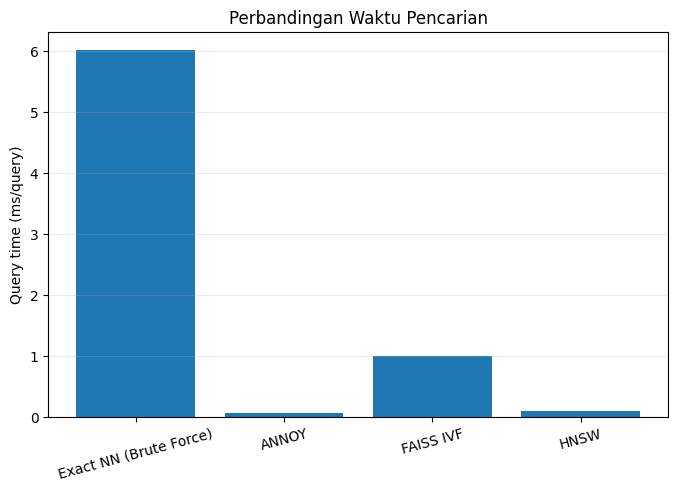

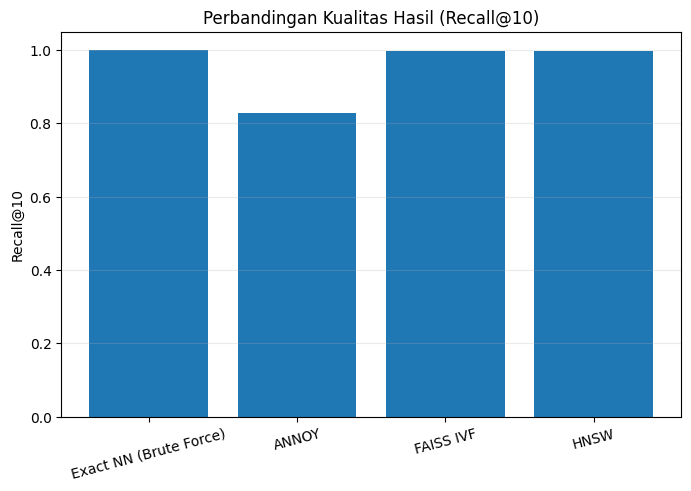

In [14]:
plt.figure(figsize=(8, 5))
plt.bar(comparison['Metode'], comparison['Query time (ms/query)'])
plt.ylabel('Query time (ms/query)')
plt.title('Perbandingan Waktu Pencarian')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(comparison['Metode'], comparison['Recall@10'])
plt.ylabel('Recall@10')
plt.ylim(0, 1.05)
plt.title('Perbandingan Kualitas Hasil (Recall@10)')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.show()

## 13. Menampilkan Track yang Paling Mirip
Hasil indeks tetangga dapat dipetakan kembali ke baris dataset. Jika dataset memiliki kolom judul track atau nama artis, tampilkan kolom tersebut sebagai informasi tambahan. Kolom metadata tidak digunakan sebagai fitur pencarian.

In [15]:
metadata_cols = [c for c in ['track_name', 'track_artist', 'track_album_name']
                 if c in df_clean.columns]
if metadata_cols:
    first_query_original_row = query_rows[0]
    print('Query track:')
    display(df_clean.iloc[[first_query_original_row]][metadata_cols])

    # Indeks tetangga adalah posisi dalam X_db, sehingga dipetakan ke db_rows
    neighbor_original_rows = db_rows[exact_indices[0]]
    print('10 track terdekat berdasarkan Exact NN:')
    display(df_clean.iloc[neighbor_original_rows][metadata_cols].reset_index(drop=True))
else:
    print('Kolom metadata track_name/track_artist tidak ditemukan. '
          'Hasil indeks numerik tetap dapat dibandingkan.')

Kolom metadata track_name/track_artist tidak ditemukan. Hasil indeks numerik tetap dapat dibandingkan.


## 14. Kesimpulan

Eksperimen ini membandingkan Exact NN dan tiga metode ANN pada sembilan fitur audio Micro Spotify yang telah distandarisasi. Exact NN menjadi acuan hasil pencarian, sedangkan ANNOY, FAISS IVF, dan HNSW dievaluasi berdasarkan waktu pembangunan indeks, waktu pencarian, serta Recall@10. Kesimpulan akhir harus ditulis berdasarkan tabel dan grafik yang dihasilkan dari dataset yang benar-benar digunakan.

## Catatan Pelaksanaan dan Interpretasi
- Pastikan file yang digunakan adalah dataset pertama dari tautan Kaggle pada modul.
- Jika nama file berbeda, ubah `CSV_PATH` pada Langkah 3.
- Jika kolom fitur tidak ditemukan, periksa nama kolom CSV dan pastikan dataset sesuai.
- Dataset besar dapat membutuhkan RAM dan waktu cukup besar, terutama saat Exact NN menghitung ground truth dan HNSW membangun indeks.
- Untuk pengujian awal, kurangi `N_QUERIES` menjadi 20; untuk laporan akhir, gunakan jumlah query yang memadai dan catat konfigurasi tersebut.
- Build time ANNOY mencakup add/build; FAISS mencakup train/add; HNSW mencakup init/add. Karena prosesnya berbeda, jelaskan definisi waktu saat membahas hasil.
- Query time adalah rata-rata waktu untuk satu query dari batch query yang sama.
- Hasil exact dan ANN memakai database serta query yang sama, sehingga Recall@10 dapat dibandingkan secara adil.
- Waktu dipengaruhi perangkat, versi library, dan beban runtime; jangan menyalin angka hasil dari perangkat lain.